In [37]:
from ase.io import read, write
from ase.visualize import view
import nglview
import pymbar
import numpy as np
from pathlib import Path
from pymbar import timeseries, MBAR
import matplotlib.pyplot as plt

In [19]:
first_window = read("traj_files/traj_window_00_cv_-4.07.traj", index=":")


v = view(first_window, viewer='ngl')

# Use v.view if ASE wraps the widget in an HBox/VBox, otherwise use v directly
widget = v.view if hasattr(v, 'view') else v
widget.clear_representations()
widget.add_representation("ball+stick", scale=0.75)
widget.add_label(
    color="black",
    labelType="text",
    labelText=[str(i) for i in range(len(first_window))],
    zOffset=1.0,
    attachment="middle_center",
    radius=0.8
)
v

# Window Correlation Analysis with pymbar

equil. frames: 0 g: 3.2685254 indep. samples: 307
Collective Variable Mean:  1.1386994824407761
Collective Variable Standard Deviation:  0.07831307141389396


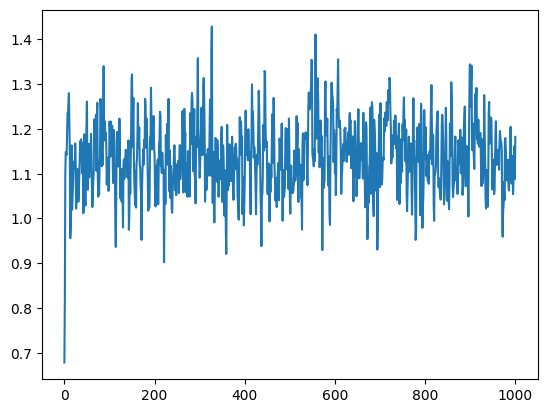

In [15]:
from pymbar import timeseries, MBAR
import numpy as np
import matplotlib.pyplot as plt

window_traj = "traj_window_26_cv_0.68.traj" # Enter window trajectory
window = read(window_traj, index=":")

kB = 0.0083144626
T = 25 + 273.15
beta = 1.0 / (kB * T)

cv_k = np.zeros(len(window))

i = 0

for atoms in window:
    d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
    cv_k[i] = d
    i += 1

sub_cv = []

t0, g, neff = timeseries.detect_equilibration(cv_k)
x_eq = cv_k[t0:]
idx = timeseries.subsample_correlated_data(x_eq, g=g)
sub_cv.append(x_eq[idx])
print("equil. frames:", t0, "g:", g, "indep. samples:", len(idx))
print("Collective Variable Mean: ",np.mean(cv_k))
print("Collective Variable Standard Deviation: ",np.std(cv_k))
plt.plot(cv_k)
plt.show()

# Summary of Stats Correlation Data:

## 1st  Image: equil. frames: 0  g: 116.84275 indep. samples: 172
## 9th  Image: equil. frames: 10 g: 3.4489763 indep. samples: 288
## 16th Image: equil. frames: 64 g: 1.4240708 indep. samples: 658
## 26th Image: equil. frames: 0  g: 3.2685254 indep. samples: 307
## 36th Image: equil. frames: 0  g: 7.4876857 indep. samples: 134

In [70]:
cv_0s = np.loadtxt('centers.txt')
cv_xs = np.zeros((len(cv_0s), 1001))
cv_xs_means = np.zeros(len(cv_0s))

traj_files = sorted(Path('traj_files/').glob('traj_window_*_cv_*.traj'))
u_kn = np.zeros((len(cv_0s), 1001))

for i, traj_file in enumerate(traj_files): 
    window = read(str(traj_file), index=":")
    for j, atoms in enumerate(window):
        d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
        cv_xs[i,j] = d
        u_kn[i,j] = atoms.get_potential_energy()
    cv_xs_means[i] = cv_xs[i].mean()

/tmp/ipykernel_1899/2447562206.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u_kn[i,j] = atoms.get_potential_energy()


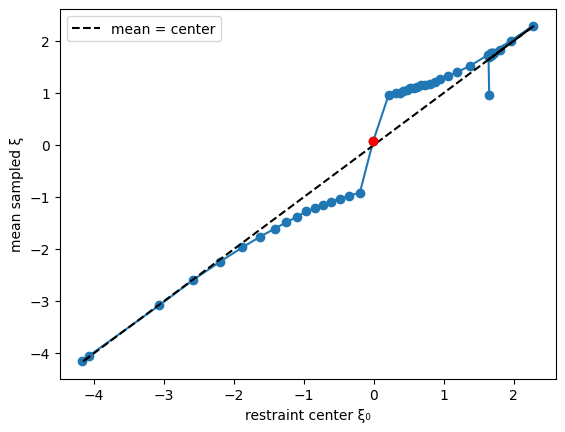

In [61]:
plt.plot(cv_0s, cv_xs_means, "o-")
plt.plot(cv_0s, cv_0s, "k--", label="mean = center")
plt.plot(cv_0s[17], cv_xs_means[17], "o-", c="red")
plt.xlabel("restraint center ξ₀")
plt.ylabel("mean sampled ξ")
plt.legend()
plt.show()

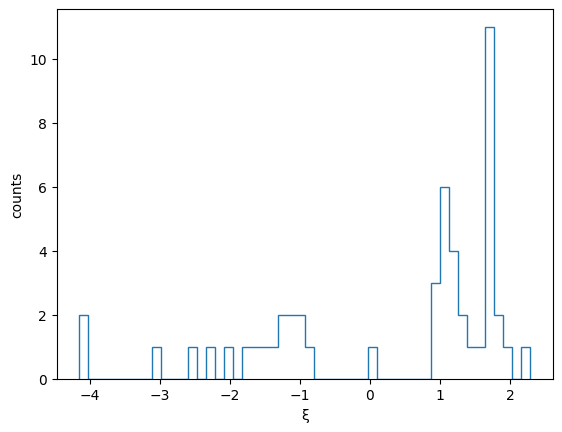

In [68]:
plt.hist(cv_xs_means, bins=50, histtype="step", density=False)
plt.xlabel("ξ")
plt.ylabel("counts")
plt.show()

In [82]:
N_k = np.full(50,1001)
print(N_k.sum())
print(np.shape(u_kn))
MBAR(u_kn, N_k)

50050
(50, 1001)


ParameterError: The sum of all N_k must equal the total number of samples (length of second dimension of u_kn.